<br>

# `#Normal Conv vs Depthwize Conv vs Point-wize vs Haar Conv:`

<br>

`This code is from the (CNN and Advance CNN Notes)`

<br>

In [2]:

import torch 
import torch.nn as nn 
import  torch.functional as F 




<br>

# `#01: Normal Convolution`

<br>

In [3]:

filters = torch.tensor(
    [
    [[1,1],
    [1,1]],
    [[1,1],
    [1,1]],
    [[1,1],
    [1,1]],
    ],
    dtype=torch.float32
)

print("filter shape: ",filters.shape)

image = torch.tensor([
    [
        [1,2,3,4],
        [5,6,7,8],
        [9,10,11,12],
        [13,14,15,16]
    ],[
        [17,18,19,20],
        [21,22,23,24],
        [25,26,27,28],
        [29,30,31,32]
    ],[
        [33,34,35,36],
        [37,38,39,40],
        [41,42,43,44],
        [45,46,47,48]
    ],
],
dtype=torch.float32
)
print("input image shape: ",image.shape)

# we are using only one filter that's why out_channels=1:
conv = nn.Conv2d(in_channels=3,out_channels=1,kernel_size=2,stride=1,bias=False)

# add parameter to our conv -> just only the filters
conv.weight = nn.Parameter(filters.unsqueeze(0))

output = conv(image)


# here, we are getting output of 1 one only: 
print(output)


filter shape:  torch.Size([3, 2, 2])
input image shape:  torch.Size([3, 4, 4])
tensor([[[234., 246., 258.],
         [282., 294., 306.],
         [330., 342., 354.]]], grad_fn=<SqueezeBackward1>)


<br>

### `-1.1: Normally, filter or kernel is odd dimention । (1x1),(3x3),(5x5) । Here, using padding introduce noise to our image. that's a bad things.`


<br>

In [4]:

# input size < output size.
# That's why we generally use odd size kernel bro.
# we are using only one filter that's why out_channels=1:
conv = nn.Conv2d(in_channels=3,out_channels=1,padding=1,stride=1,kernel_size=2,bias=False)

# add parameter to our conv -> just only the filters
conv.weight = nn.Parameter(filters.unsqueeze(0))

output = conv(image)
print(output)



tensor([[[ 51., 105., 111., 117.,  60.],
         [114., 234., 246., 258., 132.],
         [138., 282., 294., 306., 156.],
         [162., 330., 342., 354., 180.],
         [ 87., 177., 183., 189.,  96.]]], grad_fn=<SqueezeBackward1>)


<br>

### `-1.2: Let's use an odd dimention kernel and see the difference.`

<br>



In [5]:

print("Input shape: ",image.shape)

conv = nn.Conv2d(in_channels=3,out_channels=3,padding=1,stride=1,kernel_size=3,bias=False)

output = conv(image)
print("Output Shape: ",output.shape)

print(output)


Input shape:  torch.Size([3, 4, 4])
Output Shape:  torch.Size([3, 4, 4])
tensor([[[ 3.9022e+00, -3.8619e+00, -3.8875e+00, -7.2416e+00],
         [ 4.3413e+00, -1.1456e+01, -1.1894e+01, -1.1079e+01],
         [ 3.9576e+00, -1.3209e+01, -1.3647e+01, -1.1607e+01],
         [-7.1413e-02, -8.6224e+00, -8.8756e+00, -1.3174e+00]],

        [[-3.5641e+00, -1.2852e+00, -1.4387e+00,  1.3475e+00],
         [-1.9520e+00,  8.7479e+00,  9.1234e+00,  1.3944e+01],
         [-2.0894e+00,  1.0250e+01,  1.0625e+01,  1.6038e+01],
         [-2.6537e+00, -1.0640e-02,  2.4105e-01,  7.2337e+00]],

        [[ 7.3555e+00,  1.6050e+01,  1.6197e+01,  1.5294e+01],
         [ 3.7751e+00,  1.6656e+01,  1.6897e+01,  2.1907e+01],
         [ 3.2215e+00,  1.7620e+01,  1.7861e+01,  2.3945e+01],
         [-9.1899e-01,  1.2512e+01,  1.2872e+01,  2.3343e+01]]],
       grad_fn=<SqueezeBackward1>)


<br>

# `#02: Depthwize convolution operation`

<br>

In [6]:

import torch
import torch.nn as nn

filters = torch.tensor(
    [
        [[1, 1], [1, 1]], 
        [[1, 1], [1, 1]], 
        [[1, 1], [1, 1]]
        ], dtype=torch.float32
)
print("filter size: ",filters.shape)
image = torch.tensor(
    [
        [[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12], [13, 14, 15, 16]],
        [
            [17, 18, 19, 20],
            [21, 222, 23, 24],
            [25, 26, 27, 28],
            [29, 30, 31, 32],
        ],
        [[33, 34, 35, 36], [37, 38, 39, 40], [41, 42, 43, 44], [45, 46, 47, 48]],
    ],
    dtype=torch.float32,
)

total_filters = 3

# Depthwise Convolution Setup
depthConv = nn.Conv2d(
    in_channels=3,
    stride=1,
    out_channels=total_filters,
    kernel_size=2,  
    groups=total_filters, #  for depthwise  groups = in_channels
    bias=False,
)


depthConv.weight = nn.Parameter(filters.unsqueeze(1))
output = depthConv(image)

print("Output Shape:", output.shape)  

# here we are getting output: 3 channels
print(output)


filter size:  torch.Size([3, 2, 2])
Output Shape: torch.Size([3, 3, 3])
tensor([[[ 14.,  18.,  22.],
         [ 30.,  34.,  38.],
         [ 46.,  50.,  54.]],

        [[278., 282.,  86.],
         [294., 298., 102.],
         [110., 114., 118.]],

        [[142., 146., 150.],
         [158., 162., 166.],
         [174., 178., 182.]]], grad_fn=<SqueezeBackward1>)


<br>

### `Adding a filter in depthwize convolution:`

<br>

In [7]:


# Depthwise Convolution Setup
depthConv = nn.Conv2d(
    in_channels=3,
    out_channels=total_filters,
    stride=1,
    kernel_size=2,  
    groups=total_filters, #  for depthwise  groups = in_channels
    padding=1,
    bias=False,
)


depthConv.weight = nn.Parameter(filters.unsqueeze(1))
output = depthConv(image)

print("Output Shape:", output.shape)  

# here we are getting output: 3 channels
print(output)


Output Shape: torch.Size([3, 5, 5])
tensor([[[  1.,   3.,   5.,   7.,   4.],
         [  6.,  14.,  18.,  22.,  12.],
         [ 14.,  30.,  34.,  38.,  20.],
         [ 22.,  46.,  50.,  54.,  28.],
         [ 13.,  27.,  29.,  31.,  16.]],

        [[ 17.,  35.,  37.,  39.,  20.],
         [ 38., 278., 282.,  86.,  44.],
         [ 46., 294., 298., 102.,  52.],
         [ 54., 110., 114., 118.,  60.],
         [ 29.,  59.,  61.,  63.,  32.]],

        [[ 33.,  67.,  69.,  71.,  36.],
         [ 70., 142., 146., 150.,  76.],
         [ 78., 158., 162., 166.,  84.],
         [ 86., 174., 178., 182.,  92.],
         [ 45.,  91.,  93.,  95.,  48.]]], grad_fn=<SqueezeBackward1>)


<br>

# `#03: Haar Filters`

<br>

In [8]:

# revise how stack works:
a = torch.rand(size=(2,2))
b = torch.rand(size=(2,2))

print(a)
print(b)

print("Default dim=0: \n",torch.stack([a,b]))
print("dim=1: \n",torch.stack([a,b],dim=1))



tensor([[0.6054, 0.4984],
        [0.2929, 0.1633]])
tensor([[0.9794, 0.1118],
        [0.3364, 0.9480]])
Default dim=0: 
 tensor([[[0.6054, 0.4984],
         [0.2929, 0.1633]],

        [[0.9794, 0.1118],
         [0.3364, 0.9480]]])
dim=1: 
 tensor([[[0.6054, 0.4984],
         [0.9794, 0.1118]],

        [[0.2929, 0.1633],
         [0.3364, 0.9480]]])


In [9]:

# revise how unsqueeze work:
a = torch.rand(size=(2,3,2))
print(a.shape)
print("==============a==============")
print(a)
print("==============a[0]==============")
print(a[0])
print("==============a[1]==============")
print(a[1])
print("==============a[0][2]==============")
print(a[0][2])

print()
print("==============X==============")
# dim0=2,dim1=3, dim2=2
# unsqueeze on 0 dim means: (1,2,3,2)
print(a.unsqueeze(0).shape)
print(a.unsqueeze(0))

print()
print(a.unsqueeze(1).shape)
print(a.unsqueeze(1))


torch.Size([2, 3, 2])
==============a==============
tensor([[[0.1330, 0.6624],
         [0.4059, 0.7133],
         [0.3864, 0.3243]],

        [[0.4592, 0.7142],
         [0.6382, 0.6150],
         [0.8307, 0.0608]]])
==============a[0]==============
tensor([[0.1330, 0.6624],
        [0.4059, 0.7133],
        [0.3864, 0.3243]])
==============a[1]==============
tensor([[0.4592, 0.7142],
        [0.6382, 0.6150],
        [0.8307, 0.0608]])
==============a[0][2]==============
tensor([0.3864, 0.3243])

==============X==============
torch.Size([1, 2, 3, 2])
tensor([[[[0.1330, 0.6624],
          [0.4059, 0.7133],
          [0.3864, 0.3243]],

         [[0.4592, 0.7142],
          [0.6382, 0.6150],
          [0.8307, 0.0608]]]])

torch.Size([2, 1, 3, 2])
tensor([[[[0.1330, 0.6624],
          [0.4059, 0.7133],
          [0.3864, 0.3243]]],


        [[[0.4592, 0.7142],
          [0.6382, 0.6150],
          [0.8307, 0.0608]]]])


In [10]:
def _haar_filters() -> torch.Tensor:
    """The 4 orthonormal 2x2 Haar filters, shape (4, 1, 2, 2)."""
    ll = torch.tensor([[ 1.,  1.], [ 1.,  1.]])   # low-low  : average (blurred image)
    lh = torch.tensor([[ 1.,  1.], [-1., -1.]])   # low-high : top - bottom  -> horizontal edges
    hl = torch.tensor([[ 1., -1.], [ 1., -1.]])   # high-low : left - right  -> vertical edges
    hh = torch.tensor([[ 1., -1.], [-1.,  1.]])   # high-high: diagonal      -> diagonal edges
    stack_mat = torch.stack([ll,lh,hl,hh],dim=0) # 4,2,2
    # why unsqeee cause,conv2d need dim 4 dimentions:
    return (stack_mat * 0.5).unsqueeze(1)  # 4,1,2,2 

print(_haar_filters())
print(_haar_filters()[0])


tensor([[[[ 0.5000,  0.5000],
          [ 0.5000,  0.5000]]],


        [[[ 0.5000,  0.5000],
          [-0.5000, -0.5000]]],


        [[[ 0.5000, -0.5000],
          [ 0.5000, -0.5000]]],


        [[[ 0.5000, -0.5000],
          [-0.5000,  0.5000]]]])
tensor([[[0.5000, 0.5000],
         [0.5000, 0.5000]]])


In [11]:

# step: 1 doing conv witth stride 2 and with depwize conv:
print("image size: ",image.shape)
in_channel = 3 
depthwize_conv = nn.Conv2d(in_channels=in_channel,stride=2,out_channels=in_channel*4,kernel_size=2,groups=in_channel,bias=False)
depthwize_conv.weight = nn.Parameter(_haar_filters().repeat(in_channel,1,1,1),requires_grad=False)
print("modified kernel: ",depthwize_conv.weight.shape)

output = depthwize_conv(image.unsqueeze(0))
print("output shape: ",output.shape)
output



image size:  torch.Size([3, 4, 4])
modified kernel:  torch.Size([12, 1, 2, 2])
output shape:  torch.Size([1, 12, 2, 2])


tensor([[[[   7.,   11.],
          [  23.,   27.]],

         [[  -4.,   -4.],
          [  -4.,   -4.]],

         [[  -1.,   -1.],
          [  -1.,   -1.]],

         [[   0.,    0.],
          [   0.,    0.]],

         [[ 139.,   43.],
          [  55.,   59.]],

         [[-104.,   -4.],
          [  -4.,   -4.]],

         [[-101.,   -1.],
          [  -1.,   -1.]],

         [[ 100.,    0.],
          [   0.,    0.]],

         [[  71.,   75.],
          [  87.,   91.]],

         [[  -4.,   -4.],
          [  -4.,   -4.]],

         [[  -1.,   -1.],
          [  -1.,   -1.]],

         [[   0.,    0.],
          [   0.,    0.]]]])

In [12]:
"""
Har DWT(Descreate Wavelet Transformation):
- kernel: 2x2
- stride: 2
- depthwise.
- weightfixed

-kernel:
{
[LL LH]
[HL HH]
}

"""

def _haar_filters() -> torch.Tensor:
    """The 4 orthonormal 2x2 Haar filters, shape (4, 1, 2, 2)."""
    ll = torch.tensor([[ 1.,  1.], [ 1.,  1.]])   # low-low  : average (blurred image)
    lh = torch.tensor([[ 1.,  1.], [-1., -1.]])   # low-high : top - bottom  -> horizontal edges
    hl = torch.tensor([[ 1., -1.], [ 1., -1.]])   # high-low : left - right  -> vertical edges
    hh = torch.tensor([[ 1., -1.], [-1.,  1.]])   # high-high: diagonal      -> diagonal edges
    return (torch.stack([ll, lh, hl, hh]) * 0.5).unsqueeze(1)   # 0.5 makes it orthonormal


print("filter kernel size: ", _haar_filters().size())
print("filter kernel size: \n", _haar_filters())


class HaarTransform(nn.Module):
    """Forward Haar DWT: (B, C, H, W) -> (B, 4C, H/2, W/2)"""

    def __init__(self, in_channels: int):
        super().__init__()
        self.in_channels = in_channels
        out_channels = in_channels * 4

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=2,
            stride=2,
            padding=0,
            #as haar is depthwise conv
            groups=in_channels,
            bias=False,
        )

        with torch.no_grad():
            # weight shape for depthwise conv: (out_channels, in_channels/groups = 1, 2, 2)
            # (4C, 1, 2, 2)
            weight = _haar_filters().repeat(in_channels, 1, 1, 1)
            self.conv.weight.copy_(weight)
        # fixed weights, the optimizer won't change them
        self.conv.weight.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Odd H or W? Pad 1 pixel so stride-2 doesn't drop the last row/column
        # or for the pixel loss will not happend
        h, w = x.shape[-2:]
        if h % 2 or w % 2:
            x = F.pad(x, (0, w % 2, 0, h % 2), mode="reflect")
        return self.conv(x)

    @staticmethod
    def split_bands(y: torch.Tensor):
        """(B, 4C, H, W) -> LL, LH, HL, HH, each (B, C, H, W)"""
        # conv out: 1,12,2,2:
        # return: [1,3,2,2] <---> [1,3,2,2] <---> [1,3,2,2] <---> [1,3,2,2]
        b, c4, h, w = y.shape
        y = y.view(b, c4 // 4, 4, h, w)
        return y[:, :, 0], y[:, :, 1], y[:, :, 2], y[:, :, 3]


class InverseHaarTransform(nn.Module):
    """Inverse Haar DWT: (B, 4C, H/2, W/2) -> (B, C, H, W). Exact reconstruction."""

    def __init__(self, in_channels: int):   # in_channels = C of the ORIGINAL image
        super().__init__()
        self.deconv = nn.ConvTranspose2d(
            in_channels=in_channels * 4,
            out_channels=in_channels,
            kernel_size=2,
            stride=2,
            groups=in_channels,
            bias=False,
        )
        with torch.no_grad():
            self.deconv.weight.copy_(_haar_filters().repeat(in_channels, 1, 1, 1))
        self.deconv.weight.requires_grad_(False)

    def forward(self, y: torch.Tensor) -> torch.Tensor:
        return self.deconv(y)


# ---------------- Quick test ----------------
x = torch.randn(2, 3, 64, 64)            # batch of 2 RGB images
dwt, idwt = HaarTransform(3), InverseHaarTransform(3)

y = dwt(x)
LL, LH, HL, HH = HaarTransform.split_bands(y)
x_rec = idwt(y)

print("input :", tuple(x.shape))          # (2, 3, 64, 64)
print("DWT   :", tuple(y.shape))          # (2, 12, 32, 32)
print("LL    :", tuple(LL.shape))         # (2, 3, 32, 32)
print("max reconstruction error:", (x - x_rec).abs().max().item())   # ~1e-7
print("trainable params:", sum(p.numel() for p in dwt.parameters() if p.requires_grad))



filter kernel size:  torch.Size([4, 1, 2, 2])
filter kernel size: 
 tensor([[[[ 0.5000,  0.5000],
          [ 0.5000,  0.5000]]],


        [[[ 0.5000,  0.5000],
          [-0.5000, -0.5000]]],


        [[[ 0.5000, -0.5000],
          [ 0.5000, -0.5000]]],


        [[[ 0.5000, -0.5000],
          [-0.5000,  0.5000]]]])


input : (2, 3, 64, 64)
DWT   : (2, 12, 32, 32)
LL    : (2, 3, 32, 32)
max reconstruction error: 2.905726432800293e-07
trainable params: 0


image: (1, 3, 512, 512) -> each band: (1, 3, 256, 256)


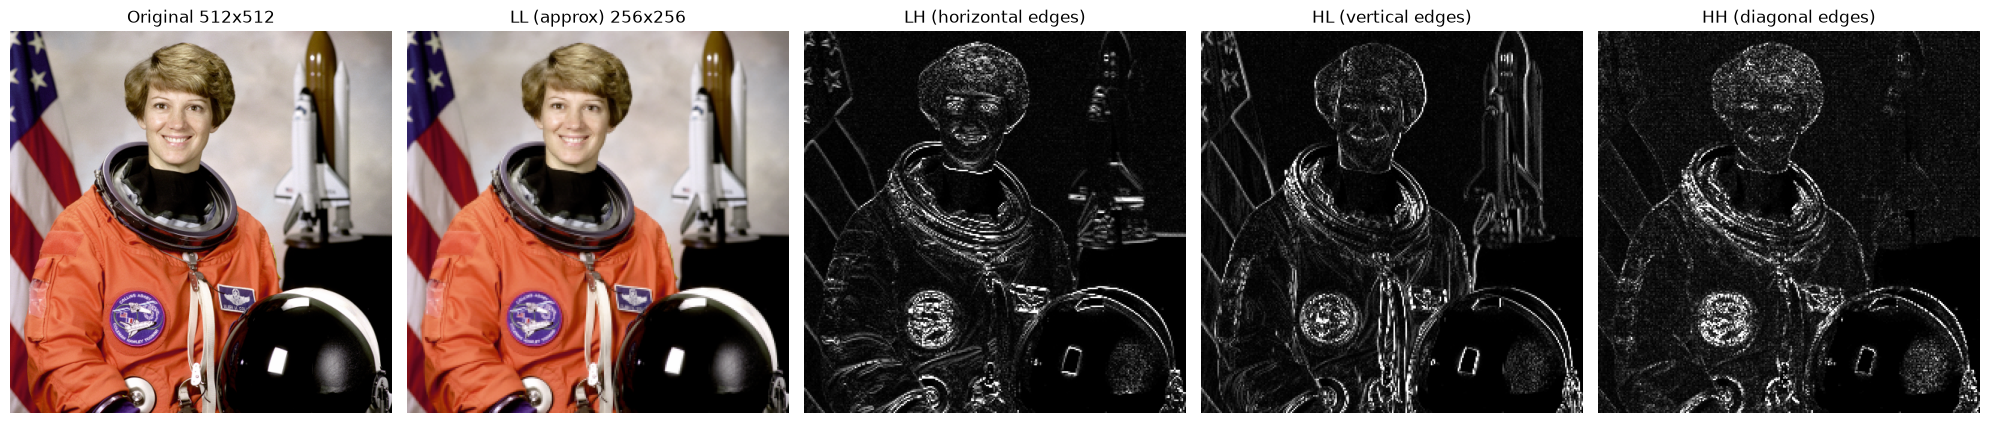

In [14]:

import numpy as np 
from skimage import data
import matplotlib.pyplot as plt 

# Load: (512, 512, 3) uint8 -> (1, 3, 512, 512) float in [0, 1]
img_np = data.astronaut()
img = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float() / 255.0

dwt = HaarTransform(in_channels=3)
with torch.no_grad():
    LL, LH, HL, HH = HaarTransform.split_bands(dwt(img))

print("image:", tuple(img.shape), "-> each band:", tuple(LL.shape))   # (1,3,512,512) -> (1,3,256,256)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

# Original
axes[0].imshow(img_np)
axes[0].set_title(f"Original {img_np.shape[0]}x{img_np.shape[1]}")

# LL: with the 0.5 factor, LL = 2 * (average of 4 pixels), so divide by 2 to get back to [0, 1]
ll_rgb = (LL[0] / 2).permute(1, 2, 0).clamp(0, 1).numpy()
axes[1].imshow(ll_rgb)
axes[1].set_title(f"LL (approx) {ll_rgb.shape[0]}x{ll_rgb.shape[1]}")

# Detail bands: show edge strength = |value| averaged over RGB
for ax, band, name in zip(axes[2:], [LH, HL, HH], ["LH (horizontal edges)", "HL (vertical edges)", "HH (diagonal edges)"]):
    b = band[0].abs().mean(0).numpy()
    ax.imshow(b, cmap="gray", vmin=0, vmax=np.percentile(b, 99))   # clip top 1% so weak edges are visible
    ax.set_title(name)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
